In [1]:
from dotenv import dotenv_values
from openai import OpenAI
from IPython.display import Markdown, Image
import base64

In [2]:
env = dotenv_values("../../.env")
openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

In [9]:
def prepare_image_for_open_ai(image_path):
    with open(image_path, "rb") as f:
        image_bytes = f.read()

    image_data = base64.b64encode(image_bytes).decode('utf-8')

    return f"data:image/png;base64,{image_data}"

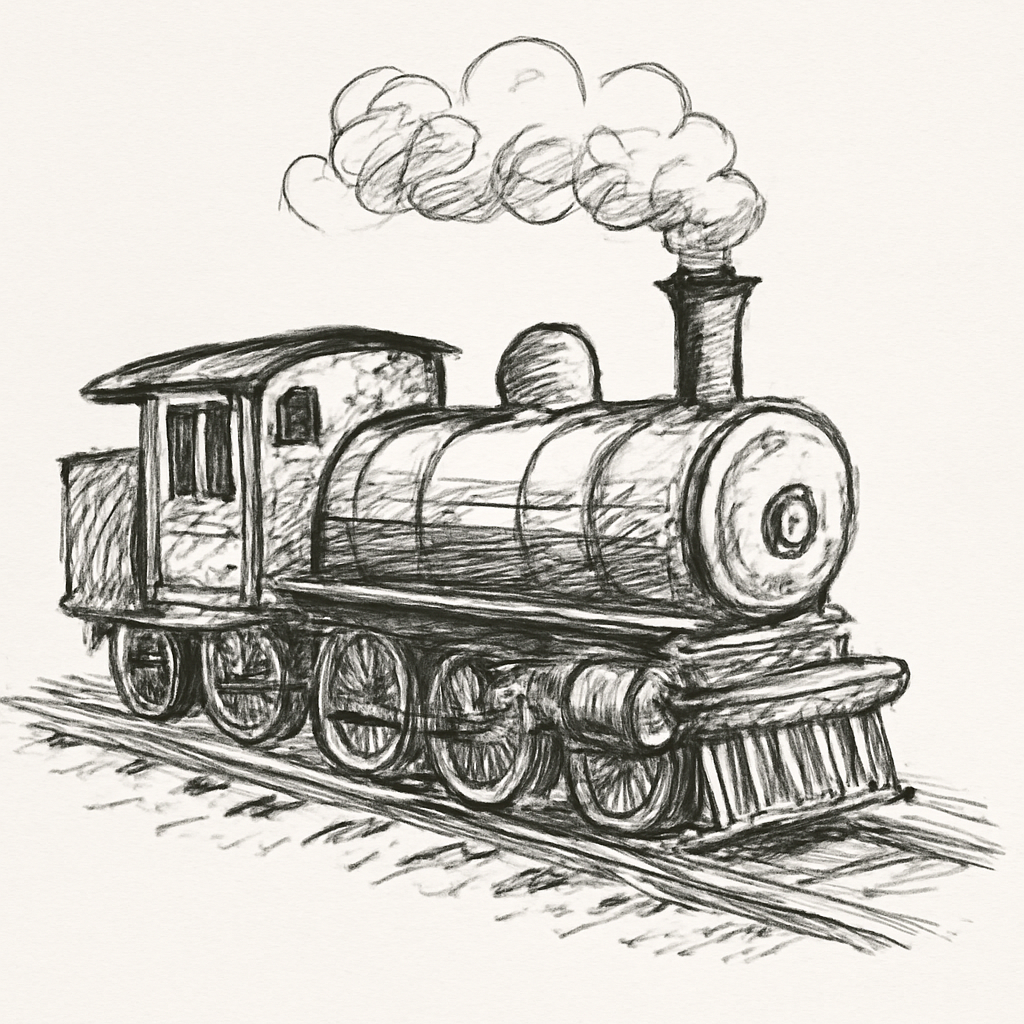

In [10]:
Image("rysunek_pociagu.png")

In [11]:
response = openai_client.chat.completions.create(
    model="gpt-4o-mini",
    temperature=0,
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": "Stwórz opis obrazka."
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": prepare_image_for_open_ai("rysunek_pociagu.png"),
                        "detail": "high"
                    }
                }
            ]
        }
    ]
)

In [12]:
Markdown(response.choices[0].message.content)

Obrazek przedstawia klasyczną lokomotywę parową, narysowaną w stylu szkicu. Lokomotywa ma charakterystyczny cylindryczny kształt, z dużymi kołami i dymiącym kominem, z którego wydobywa się para. W tle widać tor kolejowy, co sugeruje, że lokomotywa jest w ruchu lub gotowa do jazdy. Całość utrzymana jest w monochromatycznej kolorystyce, co nadaje jej nostalgiczny i retro klimat.

In [13]:
response.usage

CompletionUsage(completion_tokens=119, prompt_tokens=25516, total_tokens=25635, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=0, text_tokens=None), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=None, cached_tokens=0, image_tokens=None, text_tokens=None))

In [14]:
def describe_image(image_path):
    response = openai_client.chat.completions.create(
        model="gpt-4o-mini",
        temperature=0,
        messages=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": "Stwórz opis obrazka."
                    },
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": prepare_image_for_open_ai("rysunek_pociagu.png"),
                            "detail": "high"
                        }
                    }
                ]
            }
        ]
    )

    return response.choices[0].message.content

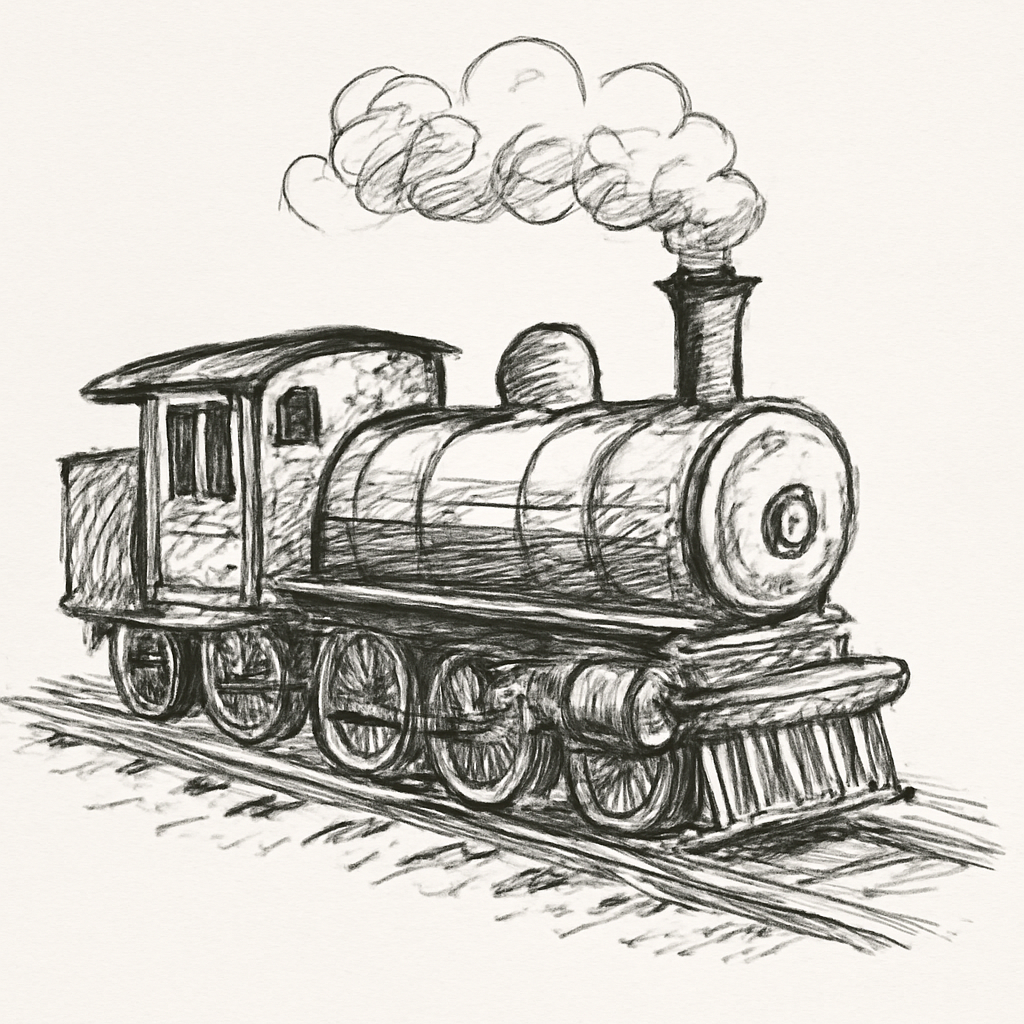

In [15]:
Image("rysunek_pociagu.png")

In [16]:
describe_image("rysunek_pociagu.png")

'Obrazek przedstawia klasyczną lokomotywę parową, narysowaną w stylu szkicu. Lokomotywa ma charakterystyczny cylindryczny kształt, z dużymi kołami i dymiącym kominem, z którego wydobywa się para. W tle widać tor kolejowy, co sugeruje, że lokomotywa jest w ruchu lub gotowa do jazdy. Całość utrzymana jest w monochromatycznej kolorystyce, co nadaje jej nostalgiczny i retro klimat.'